# Passau MedCo · Exploratory Data Analysis

Explore workforce characteristics and compare attrition across employee groups.

## 1. Imports

Import the tools for loading, displaying, and plotting data.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display

## 2. Load data

Read the employee CSV into a DataFrame.

In [2]:
csv_path = Path("data") / "employee-attrition.csv"
employees = pd.read_csv(csv_path)

## 3. Inspect structure

Show the dataset dimensions, column types, and non-null counts.

In [3]:
employees.info()

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   int64
 14  JobLevel                  1470 non-null   int64
 15

## 4. Preview data

Display selected columns for the first three employees.

In [4]:
preview_columns = ["Age", "Department", "JobRole", "OverTime", "MonthlyIncome", "Attrition"]
display(employees[preview_columns].head(3))

,Age,Department,JobRole,OverTime,MonthlyIncome,Attrition
0,41,Sales,Sales Executive,Yes,5993,Yes
1,49,Research & Development,Research Scientist,No,5130,No
2,37,Research & Development,Laboratory Technician,Yes,2090,Yes


## 5. Data preparation

Check missing values, duplicate rows, employee IDs, and target labels.

In [5]:
target_labels = set(employees["Attrition"].dropna())
quality_checks = pd.Series({
    "Missing values": employees.isna().sum().sum(),
    "Duplicate rows": employees.duplicated().sum(),
    "Duplicate employee IDs": employees["EmployeeNumber"].duplicated().sum(),
    "Missing employee IDs": employees["EmployeeNumber"].isna().sum(),
    "Missing target labels": employees["Attrition"].isna().sum(),
})
display(quality_checks.to_frame("Count"))
print("Target labels:", sorted(target_labels))

assert quality_checks.iloc[1:].eq(0).all(), "Review duplicates, IDs, or missing labels."
assert target_labels == {"Yes", "No"}, "Review the Attrition labels."

,Count
Missing values,0
Duplicate rows,0
Duplicate employee IDs,0
Missing employee IDs,0
Missing target labels,0


Target labels: ['No', 'Yes']


### Prepare the analysis table

Drop the ID and constant columns from the analysis copy, then encode attrition and group tenure into bands.

In [6]:
constant_columns = employees.columns[employees.nunique(dropna=False).eq(1)].tolist()
excluded_columns = ["EmployeeNumber", *constant_columns]
eda = employees.drop(columns=excluded_columns).copy()
eda["LeftCompany"] = eda["Attrition"].eq("Yes")
eda["TenureBand"] = pd.cut(
    eda["YearsAtCompany"],
    bins=[-1, 2, 5, 10, float("inf")],
    labels=["0–2", "3–5", "6–10", "11+"],
)

print("Excluded columns:", ", ".join(excluded_columns))
print(f"{len(eda):,} employees retained")

Excluded columns: EmployeeNumber, EmployeeCount, Over18, StandardHours
1,470 employees retained


## 6. Descriptive statistics

Summarize the target balance and the distribution of selected numeric variables.

In [7]:
attrition_counts = eda["Attrition"].value_counts().reindex(["No", "Yes"])
attrition_summary = attrition_counts.to_frame("Employees")
attrition_summary["Share (%)"] = 100 * attrition_counts / len(eda)
overall_rate = attrition_summary.loc["Yes", "Share (%)"]
display(attrition_summary.round(1))

numeric_features = ["Age", "MonthlyIncome", "YearsAtCompany", "DistanceFromHome"]
display(eda[numeric_features].describe().T.round(1))

,Employees,Share (%)
Attrition,,
No,1233,83.9
Yes,237,16.1


,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.9,9.1,18.0,30.0,36.0,43.0,60.0
MonthlyIncome,1470.0,6502.9,4708.0,1009.0,2911.0,4919.0,8379.0,19999.0
YearsAtCompany,1470.0,7.0,6.1,0.0,3.0,5.0,9.0,40.0
DistanceFromHome,1470.0,9.2,8.1,1.0,2.0,7.0,14.0,29.0


### Compare medians by attrition status

Compare typical age, income, tenure, and commute distance for employees who left or stayed.

In [8]:
medians = eda.groupby("Attrition")[numeric_features].median()
display(medians.rename(index={"No": "Stayed", "Yes": "Left"}))

,Age,MonthlyIncome,YearsAtCompany,DistanceFromHome
Attrition,,,,
Stayed,36.0,5204.0,6.0,7.0
Left,32.0,3202.0,3.0,9.0


## 7. Group comparisons

Compare attrition counts and within-group rates by role, department, overtime, travel, satisfaction, and tenure.

In [9]:
def summarize_attrition(group_columns):
    summary = (
        eda.groupby(group_columns, observed=True, dropna=False)
        .agg(Employees=("LeftCompany", "size"), Departures=("LeftCompany", "sum"))
    )
    summary["Attrition (%)"] = 100 * summary["Departures"] / summary["Employees"]
    return summary

role_summary = summarize_attrition("JobRole").sort_values("Attrition (%)", ascending=False)
display(role_summary.round(1))

group_features = ["Department", "OverTime", "BusinessTravel", "JobSatisfaction", "TenureBand"]
group_summaries = pd.concat(
    [summarize_attrition(feature) for feature in group_features],
    keys=group_features,
    names=["Feature", "Group"],
)
display(group_summaries.round(1))

,Employees,Departures,Attrition (%)
JobRole,,,
Sales Representative,83,33,39.8
Laboratory Technician,259,62,23.9
Human Resources,52,12,23.1
Sales Executive,326,57,17.5
Research Scientist,292,47,16.1
Manufacturing Director,145,10,6.9
Healthcare Representative,131,9,6.9
Manager,102,5,4.9
Research Director,80,2,2.5


Employees  Departures  Attrition (%)
Feature         Group                                                       
Department      Human Resources                63          12           19.0
                Research & Development        961         133           13.8
                Sales                         446          92           20.6
OverTime        No                           1054         110           10.4
                Yes                           416         127           30.5
BusinessTravel  Non-Travel                    150          12            8.0
                Travel_Frequently             277          69           24.9
                Travel_Rarely                1043         156           15.0
JobSatisfaction 1                             289          66           22.8
                2                             280          46           16.4
                3                             442          73           16.5
                4                             459          52           11.3
TenureBand      0–2                           342         102           29.8
                3–5                           434          60           13.8
                6–10                          448          55           12.3
                11+                           246          20            8.1

### Compare overtime within tenure bands

Group by both tenure and overtime to see where the overtime gap is largest.

In [10]:
tenure_overtime = summarize_attrition(["TenureBand", "OverTime"])
display(tenure_overtime.round(1))

Employees  Departures  Attrition (%)
TenureBand OverTime                                      
0–2        No              238          49           20.6
           Yes             104          53           51.0
3–5        No              307          24            7.8
           Yes             127          36           28.3
6–10       No              328          24            7.3
           Yes             120          31           25.8
11+        No              181          13            7.2
           Yes              65           7           10.8

### Plot the strongest group differences

Compare attrition by job role and by tenure and overtime against the overall rate.

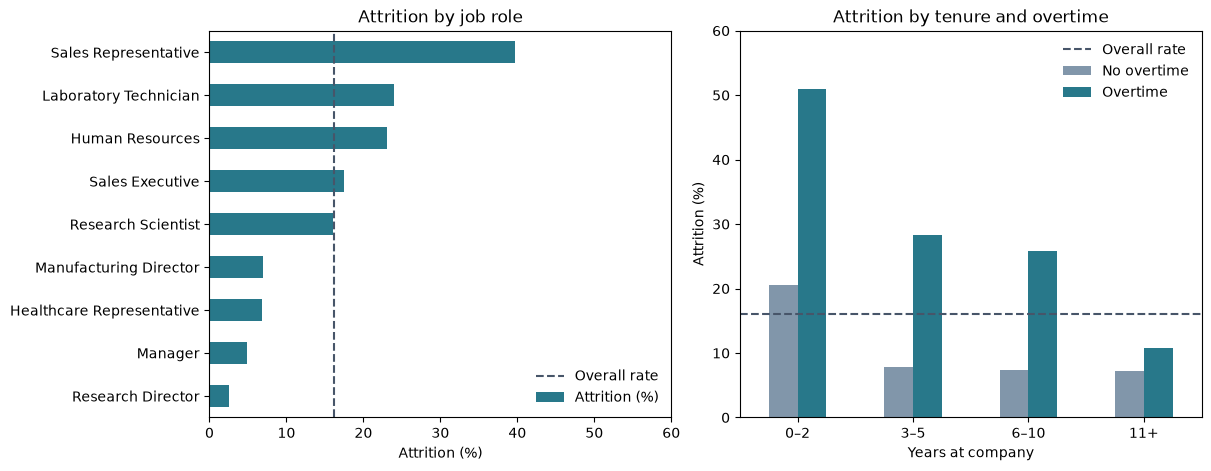

In [11]:
%matplotlib inline

fig, (role_ax, tenure_ax) = plt.subplots(1, 2, figsize=(12, 4.6), layout="constrained")

role_summary["Attrition (%)"].sort_values().plot.barh(ax=role_ax, color="#28788a")
role_ax.axvline(overall_rate, color="#475569", linestyle="--", label="Overall rate")
role_ax.set(title="Attrition by job role", xlabel="Attrition (%)", ylabel="")
role_ax.set_xlim(0, 60)
role_ax.legend(loc="lower right", frameon=False)

overtime_rates = tenure_overtime["Attrition (%)"].unstack("OverTime")
overtime_rates.rename(columns={"No": "No overtime", "Yes": "Overtime"}).plot.bar(
    ax=tenure_ax, color=["#8196aa", "#28788a"], rot=0
)
tenure_ax.axhline(overall_rate, color="#475569", linestyle="--", label="Overall rate")
tenure_ax.set(title="Attrition by tenure and overtime", xlabel="Years at company", ylabel="Attrition (%)")
tenure_ax.set_ylim(0, 60)
tenure_ax.legend(loc="upper right", frameon=False)

plt.show()

## 8. EDA takeaways

- **Workforce profile.** The median age was 36 and the median tenure was 5 years. Research & Development accounted for 961 of 1,470 employees (65.4%).
- **Overtime and tenure** show clear differences. Attrition was 30.5% with overtime and 10.4% without it. In the 0–2 year band, it reached 51.0% among employees with overtime (53 of 104).
- **Job role and travel** also stand out. Sales Representatives had the highest role-specific rate (39.8%, 33 of 83). Frequent travelers had 24.9% attrition versus 8.0% among non-travelers.
- **Age, income, and job satisfaction** are worth exploring further. Median age was 32 for employees who left and 36 for those who stayed. Median monthly income was 3,202 and 5,204, respectively. Attrition was 22.8% at the lowest satisfaction score and 11.3% at the highest.

The overall rate was 16.1%. These are associations in a single dataset. Tenure bands compare employee groups, and the CSV has no dates for tracking changes over time.